**Лабораторная работа №4. Методы цифровой фильтрации изображений**

Выполнили студенты группы 932302: Лебёдкин Владислав и Травкова Ирина

Вариант 4

In [1]:
# импорт библиотек
import cv2
import numpy as np 
import matplotlib.pyplot as plt 
import time

(np.float64(-0.5), np.float64(748.5), np.float64(1132.5), np.float64(-0.5))

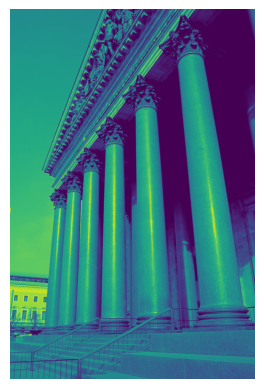

In [2]:
# загрузка изображения в градациях серого
img = cv2.imread('cv_image.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Изображение не найдено! Проверьте путь")
plt.imshow(img)
plt.axis("off")

Для 1 задания на изображение необходимо добавить шум "соль и перец". Напишем для этого функцию ``add_salt_pepper_noise``

In [3]:
def add_salt_pepper_noise(image, amount=0.05):
    noisy = np.copy(image)
    h, w = image.shape
    num_salt = int(np.ceil(amount * h * w * 0.5))
    num_pepper = int(np.ceil(amount * h * w * 0.5))
    # соль (белые пиксели)
    coords_salt = [np.random.randint(0, i - 1, num_salt) for i in image.shape]
    noisy[coords_salt[0], coords_salt[1]] = 255
    # перец (черные пиксели)
    coords_pepper = [np.random.randint(0, i - 1, num_pepper) for i in image.shape]
    noisy[coords_pepper[0], coords_pepper[1]] = 0
    return noisy

(np.float64(-0.5), np.float64(748.5), np.float64(1132.5), np.float64(-0.5))

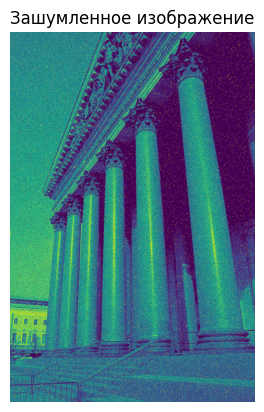

In [4]:
img_noisy = add_salt_pepper_noise(img, amount=0.05)
plt.imshow(img_noisy)
plt.title("Зашумленное изображение")
plt.axis("off")

### Задание 1. Применить фильтр Гаусса ($\sigma$ = 2) и медианный фильтр (5*5). Сравнить. 

**Гауссов фильтр** — линейный фильтр, ядро которого строится по формуле 
  двумерного гауссиана:
  
  $$G(x,y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2+y^2}{2\sigma^2}}$$
  
  Параметр σ задаёт «ширину» колокола и, соответственно, силу размытия.

**Медианный фильтр** — нелинейный фильтр, заменяющий центральный пиксель медианой значений в окне размера $N \times N$.
Для применения фильтра Гаусса используется функция ``cv2.GaussianPlur()``. Для медианного фильтра используется функция ``cv2.medianBlur()``. Функции применяются к зашумленному изображению для дальнейшего сравнения.

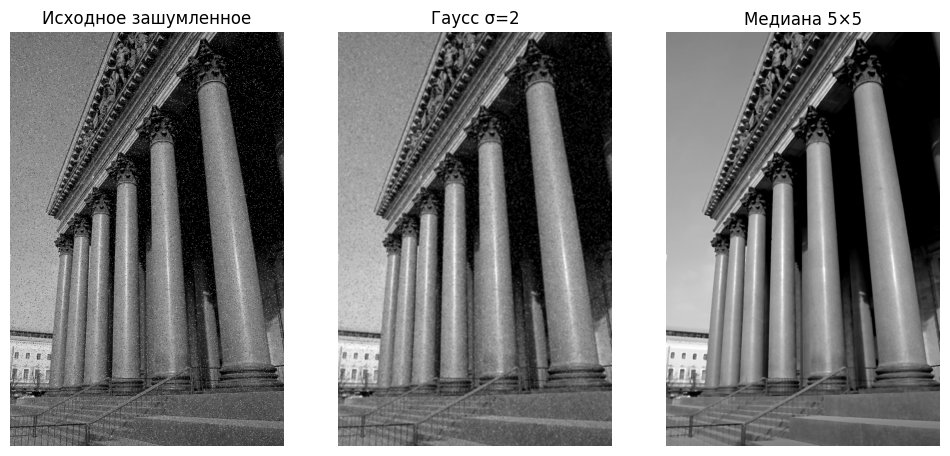

In [ ]:
gaussian = cv2.GaussianBlur(img_noisy, (5, 5), sigmaX=2.0)
median = cv2.medianBlur(img_noisy, 5)

plt.figure(figsize=(12, 6))
plt.subplot(131), plt.imshow(img_noisy, cmap='gray'), plt.title('Исходное зашумленное'), plt.axis("off")
plt.subplot(132), plt.imshow(gaussian, cmap='gray'), plt.title('Гаусс σ=2'), plt.axis("off")
plt.subplot(133), plt.imshow(median, cmap='gray'), plt.title('Медиана 5×5'), plt.axis("off")
plt.show()

**Вывод:** Гауссов фильтр размывает импульсивный шум, превращая резкие точки в мутные серые пятна. Медианный фильтр полностью устраняет шум «соль и перец», сохраняя при этом чёткость границ объектов.

### Задание 2. Выделить вертикальные границы оператором Превитта.

Оператор Превитта — градиентный фильтр первого порядка, вычисляющий приближение производной яркости изображения.

Для выделения **вертикальных границ** используется ядро, чувствительное к перепадам яркости по горизонтальной оси (градиент по X):

$$P_x = \begin{bmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{bmatrix}$$

**Алгоритм:**
1. С помощью ``np.array()`` задаем матрицу 3×3 — ядро Превитта для вертикальных границ.
2. К загруженному изображению в градациях серого применяем свёртку `cv2.filter2D()` с ядром Превитта.
3. Берём модуль результата (так как градиент может быть отрицательным) с помощью функции ``np.abs()``.
4. Нормализуем в диапазон [0, 255] с помощью ``cv2.normalize()`` для визуализации.

In [7]:
kernel_prewitt_v = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]], dtype=np.float32)
prewitt_v = cv2.filter2D(img, cv2.CV_64F, kernel_prewitt_v)
prewitt_v_abs = np.abs(prewitt_v)

prewitt_v_norm = cv2.normalize(prewitt_v_abs, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

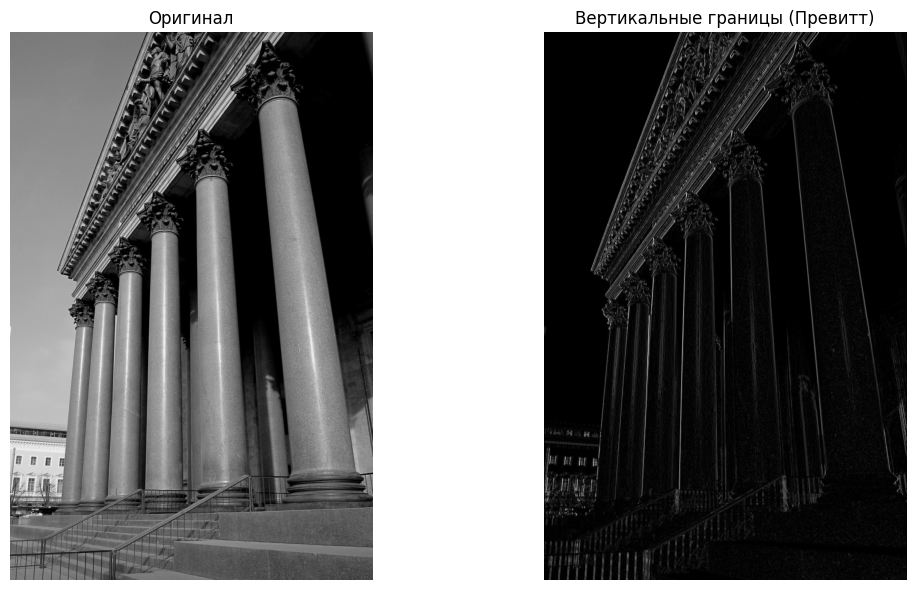

In [15]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Оригинал')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(prewitt_v_norm, cmap='gray')
plt.title('Вертикальные границы (Превитт)')
plt.axis('off')

plt.tight_layout()
plt.show()

**Вывод:** На результирующем изображении чётко видны **колонны** здания — основные вертикальные структуры. Горизонтальные элементы (ступени лестницы, карнизы) практически не выражены.

### Задание 3. Усилить резкость изображения с помощью свёртки.

### Задание 4. Сравнить скорость работы усредняющего и медианного фильтров при окне 11×11.

### Задание 5. Реализовать гауссов ВЧ-фильтр в частотной области.

**ОТВЕТЫ НА КОНТРОЛЬНЫЕ ВОПРОСЫ:**
1. Что такое фильтрация изображений и для чего она используется? Это процесс обработки пикселей цифрового изображения с помощью специальной маски (ядра). Используется для улучшения качества картинки: подавления шумов, сглаживания, повышения резкости, выделения границ и контуров объектов.

2. Чем отличается линейная фильтрация от нелинейной? Линейная фильтрация основана на операции свёртки: новый пиксель рассчитывается как взвешенная сумма соседних пикселей. Нелинейная фильтрация не использует суммирование весов; вместо этого она применяет другие операции, например, сортировку значений в окне и выбор медианы, минимума или максимума.
3. Какие виды шумов бывают на изображениях?

* Гауссовский: случайные помехи, равномерно распределенные по изображению (часто из-за плохого освещения или датчиков камеры).
* Импульсный («соль и перец»): хаотичные черные и белые точки, возникающие из-за сбоев при передаче данных или дефектов матрицы.
* Равномерный: шум, значения которого случайны в заданном диапазоне.
* Периодический: регулярные узоры или полосы (например, муар при сканировании).

4. Как размер окна фильтра влияет на результат фильтрации? Чем больше размер окна (ядра), тем сильнее эффект сглаживания и подавления шума. Однако обратная сторона медали: сильнее размываются границы объектов, теряются мелкие детали, а также увеличивается время вычислений.

5. В каких случаях предпочтительно использовать пространственную фильтрацию, а в каких — частотную? Пространственная фильтрация лучше подходит для простых локальных задач: удаления точечного шума, базового выделения границ или работы с небольшими ядрами. Частотная фильтрация незаменима для анализа глобальных периодических структур, удаления специфического периодического шума или при использовании очень больших ядер свёртки.

6. В чём принцип работы усредняющего фильтра? Он заменяет значение центрального пикселя средним арифметическим значением всех пикселей, попадающих в окно фильтра. Все коэффициенты (веса) в таком ядре одинаковы.

7. Как гауссов фильтр отличается от простого усреднения? В гауссовом фильтре веса пикселей не одинаковы: центральный пиксель имеет наибольший вес, а вес соседних пикселей плавно убывает с расстоянием от центра (по колоколообразной кривой). Это обеспечивает более естественное и плавное сглаживание с лучшим сохранением контуров.

8. Для какого типа шума эффективен медианный фильтр? Он исключительно эффективен для удаления импульсного шума типа «соль и перец». При сортировке пикселей в окне одиночные черные или белые выбросы просто отбрасываются, при этом истинные резкие границы объектов сохраняются.

9. Что делают операторы Собеля и Превитта? Это градиентные фильтры. Они вычисляют приближение первой производной яркости изображения по осям X и Y. Проще говоря, они реагируют на резкие перепады яркости и используются для выделения границ (контуров) объектов.

10. Чем оператор Лапласа отличается от оператора Собеля? Оператор Собеля вычисляет первую производную (показывает направление и силу перепада яркости). Оператор Лапласа вычисляет вторую производную. Он не зависит от направления (изотропен) и выделяет именно места резкого изменения градиента (замкнутые контуры), но при этом он гораздо сильнее чувствителен к шуму.

11. Как реализуется фильтр повышения резкости (sharpen, unsharp masking)? Чаще всего путем вычитания из исходного изображения его размытой копии (или сложения исходного изображения с результатом фильтра высоких частот, например, Лапласа). В виде ядра свёртки это матрица с большим положительным числом в центре и отрицательными числами по краям.

12. Как интерпретировать низкие и высокие частоты изображения? Низкие частоты отвечают за плавные, медленные изменения яркости и крупные однородные области (например, небо, фон, тени). Высокие частоты отвечают за резкие перепады яркости, мелкие детали, текстуры и границы объектов.

13. Как выполняется переход от пространственной области к частотной (какое преобразование используется)? С помощью Дискретного Преобразования Фурье (ДПФ). На практике для значительного ускорения вычислений всегда используется алгоритм Быстрого Преобразования Фурье (БПФ).

14. Какие шаги выполняются при фильтрации изображения в частотной области?

- Применение прямого преобразования Фурье к изображению.
- Сдвиг спектра, чтобы низкие частоты оказались в центре матрицы.
- Создание маски фильтра и поэлементное умножение спектра на эту маску.
- Обратный сдвиг спектра в исходное положение.
- Применение обратного преобразования Фурье для получения отфильтрованного изображения и взятие модуля результата.

15. Чем отличается идеальный низкочастотный фильтр от гауссова НЧ-фильтра? Идеальный фильтр имеет резкий порог среза: он безоговорочно обнуляет все частоты выше заданного радиуса. Гауссов фильтр имеет плавный спад, постепенно ослабляя высокие частоты без резких обрывов.

16. Какие артефакты могут возникнуть при использовании идеального НЧ-фильтра? Эффект «звона» (рябь Гиббса). Из-за резкого обрезания спектра на границах контрастных объектов появляются паразитные светлые и темные волны или ореолы.
17. Как работает высокочастотный фильтр и для чего он применяется? Он подавляет (обнуляет или ослабляет) низкие частоты в центре спектра и пропускает или усиливает высокие частоты на периферии. Применяется для выделения границ, контуров и общего повышения резкости изображения.

18. Что такое полосовой фильтр (BPF) и где он может использоваться? Это фильтр, который пропускает только определенный диапазон частот (между нижним и верхним радиусом среза), подавляя как очень низкие, так и очень высокие частоты. Используется для выделения специфических текстур, периодических узоров или для удаления узкополосного периодического шума.

19. Какие преимущества даёт частотная фильтрация по сравнению с пространственной? Она позволяет глобально анализировать и модифицировать изображение на основе его частотного состава. Это единственный эффективный способ борьбы с периодическим шумом (например, полосами от сканера), который сложно убрать пространственными методами.

20. Почему фильтрация через БПФ может быть более эффективной при больших ядрах свёртки? Вычислительная сложность прямой пространственной свёртки растет квадратично с увеличением размера ядра (требуется огромное количество умножений). Алгоритм БПФ имеет логарифмическую сложность. Поэтому при больших размерах ядра (обычно больше 15–20 пикселей) фильтрация через частотную область работает значительно быстрее.